In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

# Fixed seeds so the results are the same every time you run the notebook
np.random.seed(42)
tf.random.set_seed(42)

print("environment set up successfully")

environment set up successfully


In [2]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["sample_data", "__pycache__"]]

    for file in files[:10]:
        print(os.path.join(root, file))

/content/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset.zip
/content/wisdm_dataset.zip
/content/.config/active_config
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/config_sentinel
/content/.config/.last_update_check.json
/content/.config/default_configs.db
/content/.config/.last_opt_in_prompt.yaml
/content/.config/gce
/content/.config/.last_survey_prompt.yaml
/content/.config/configurations/config_default
/content/.config/logs/2026.10.02/13.50.15.366402.log
/content/.config/logs/2026.10.02/13.50.08.874802.log
/content/.config/logs/2026.10.02/13.50.21.555054.log
/content/.config/logs/2026.10.02/13.49.46.128557.log
/content/.config/logs/2026.10.02/13.50.14.261149.log
/content/.config/logs/2026.10.02/13.50.21.004336.log
/content/results/model_results.json
/content/results/classification_report.json
/content/results/cnn_lstm_model.keras
/content/WISDM/WISDM-dataset-description.pdf
/content/WISDM/wisdm-dataset.zip
/content/

In [3]:
import os

for file in os.listdir("/content"):
    print(file)

.config
results
wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset.zip
WISDM
wisdm_dataset.zip
sample_data


In [4]:
import zipfile
import os

zip_path = "/content/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("Valid ZIP:", zipfile.is_zipfile(zip_path))

File exists: True
Valid ZIP: False


In [ ]:

!wget -O /content/wisdm_dataset.zip "https://archive.ics.uci.edu/static/public/507/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset.zip"

--2026-10-14 01:01:56--  https://archive.ics.uci.edu/static/public/507/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘/content/wisdm_dataset.zip’

/content/wisdm_data     [  <=>               ] 295.92M  1.40MB/s    in 35s     

2026-10-14 01:02:31 (8.49 MB/s) - ‘/content/wisdm_dataset.zip’ saved [310292805]



In [6]:
import zipfile
import os

new_zip_path = "/content/wisdm_dataset.zip"
extract_path = "/content/WISDM"

if zipfile.is_zipfile(new_zip_path):
    with zipfile.ZipFile(new_zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("Dataset successfully extracted to:", extract_path)
else:
    print("The newly downloaded file is still not a valid ZIP.")

Dataset successfully extracted to: /content/WISDM


In [7]:
import os

for root, dirs, files in os.walk("/content/WISDM"):
    for file in files:
        print(os.path.join(root, file))

/content/WISDM/WISDM-dataset-description.pdf
/content/WISDM/wisdm-dataset.zip
/content/WISDM/data/wisdm-dataset/change_raw_act.pl
/content/WISDM/data/wisdm-dataset/activity_key.txt
/content/WISDM/data/wisdm-dataset/README.txt
/content/WISDM/data/wisdm-dataset/WISDM-dataset-description.pdf
/content/WISDM/data/wisdm-dataset/.activity_key.txt.swp
/content/WISDM/data/wisdm-dataset/raw/.DS_Store
/content/WISDM/data/wisdm-dataset/raw/phone/.DS_Store
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1603_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1614_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1627_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1645_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1604_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1639_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1630_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/

In [8]:
import zipfile
import os

zip_path = "/content/WISDM/wisdm-dataset.zip"
extract_path = "/content/WISDM/data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("actual dataset extracted")

actual dataset extracted


In [9]:
import os

for root, dirs, files in os.walk("/content/WISDM/data"):
    for file in files:
        print(os.path.join(root, file))

/content/WISDM/data/wisdm-dataset/change_raw_act.pl
/content/WISDM/data/wisdm-dataset/activity_key.txt
/content/WISDM/data/wisdm-dataset/README.txt
/content/WISDM/data/wisdm-dataset/WISDM-dataset-description.pdf
/content/WISDM/data/wisdm-dataset/.activity_key.txt.swp
/content/WISDM/data/wisdm-dataset/raw/.DS_Store
/content/WISDM/data/wisdm-dataset/raw/phone/.DS_Store
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1603_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1614_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1627_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1645_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1604_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1639_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1630_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/phone/gyro/data_1600_gyro_phone.txt
/content/WISDM/data/wisdm-dataset/raw/

In [10]:
import os

base_path = "/content/WISDM/data/wisdm-dataset/raw"

for sensor in ["accel", "gyro"]:
    path = f"{base_path}/phone/{sensor}"

    print(f"\n{sensor.upper()}")
    print("Number of files:", len(os.listdir(path)))
    print("Sample files:", os.listdir(path)[:3])


ACCEL
Number of files: 52
Sample files: ['data_1618_accel_phone.txt', 'data_1611_accel_phone.txt', 'data_1613_accel_phone.txt']

GYRO
Number of files: 52
Sample files: ['data_1603_gyro_phone.txt', 'data_1614_gyro_phone.txt', 'data_1627_gyro_phone.txt']


In [11]:
import os
import pandas as pd

base_path = "/content/WISDM/data/wisdm-dataset/raw/phone"

accel_files = sorted(
    [f for f in os.listdir(f"{base_path}/accel") if f.endswith(".txt")]
)

gyro_files = sorted(
    [f for f in os.listdir(f"{base_path}/gyro") if f.endswith(".txt")]
)

print("Accelerometer files:", len(accel_files))
print("Gyroscope files:", len(gyro_files))

Accelerometer files: 51
Gyroscope files: 51


In [12]:
with open(f"{base_path}/accel/{accel_files[0]}", "r") as file:
    for _ in range(5):
        print(file.readline().strip())

1600,A,252207666810782,-0.36476135,8.793503,1.0550842;
1600,A,252207717164786,-0.8797302,9.768784,1.0169983;
1600,A,252207767518790,2.0014954,11.10907,2.619156;
1600,A,252207817872794,0.45062256,12.651642,0.18455505;
1600,A,252207868226798,-2.1643524,13.928436,-4.4224854;


In [13]:
import os
import pandas as pd

base_path = "/content/WISDM/data/wisdm-dataset/raw/phone"

def load_sensor(sensor):
    folder = f"{base_path}/{sensor}"
    data = []

    for file in os.listdir(folder):
        if not file.endswith(".txt"):
            continue

        df = pd.read_csv(
            f"{folder}/{file}",
            header=None,
            names=[
                "subject", "activity", "timestamp",
                f"{sensor}_x", f"{sensor}_y", f"{sensor}_z"
            ],
            sep=",",
            on_bad_lines="skip"
        )


        for col in [f"{sensor}_x", f"{sensor}_y", f"{sensor}_z"]:
            df[col] = pd.to_numeric(
                df[col].astype(str).str.strip().str.rstrip(";"),
                errors="coerce"
            )

        data.append(df.dropna())

    return pd.concat(data, ignore_index=True)


accel = load_sensor("accel")
gyro = load_sensor("gyro")

print("Accelerometer shape:", accel.shape)
print("Gyroscope shape:", gyro.shape)

print("\nAccelerometer sample:")
print(accel.head())

Accelerometer shape: (4804403, 6)
Gyroscope shape: (3608635, 6)

Accelerometer sample:
   subject activity        timestamp   accel_x   accel_y   accel_z
0     1618        A  775419608986314 -1.348709 -4.518112  3.989212
1     1618        A  775419659340318 -4.958740 -9.171280 -3.202957
2     1618        A  775419709694322 -5.329346 -7.373398 -1.853958
3     1618        A  775419760048326 -4.194275 -6.054520 -0.729843
4     1618        A  775419810402330 -5.509750 -7.063385 -0.167542


In [29]:


activity_map = {
    "A": "Walking",
    "B": "Jogging",
    "D": "Sitting",
    "E": "Standing"
}

accel = accel[accel["activity"].isin(activity_map)].copy()
gyro = gyro[gyro["activity"].isin(activity_map)].copy()

print("Accelerometer readings:", len(accel))
print("Gyroscope readings:", len(gyro))

print("\nActivity distribution in accelerometer data:")
print(accel["activity"].value_counts())

print("\nActivity distribution in gyroscope data:")
print(gyro["activity"].value_counts())

print("\nSelected activities:")
for code, name in activity_map.items():
    print(f"{code}: {name}")

Accelerometer readings: 1082422
Gyroscope readings: 808892

Activity distribution in accelerometer data:
activity
A    279817
E    269604
B    268409
D    264592
Name: count, dtype: int64

Activity distribution in gyroscope data:
activity
A    203919
D    202370
E    202351
B    200252
Name: count, dtype: int64

Selected activities:
A: Walking
B: Jogging
D: Sitting
E: Standing


In [15]:
print("Accelerometer timestamps:")
print(accel["timestamp"].min(), accel["timestamp"].max())

print("\nGyroscope timestamps:")
print(gyro["timestamp"].min(), gyro["timestamp"].max())

subject_id = accel["subject"].iloc[0]

print("\nAccelerometer sample intervals:")
print(
    accel[accel["subject"] == subject_id]["timestamp"]
    .diff()
    .dropna()
    .head()
)

Accelerometer timestamps:
290568502060 1819802811562000

Gyroscope timestamps:
290719564072 1819802811612000

Accelerometer sample intervals:
1    50354004.0
2    50354004.0
3    50354004.0
4    50354004.0
5    50354004.0
Name: timestamp, dtype: float64


In [16]:
import pandas as pd
import numpy as np

accel_clean = accel[
    ["subject", "activity", "timestamp",
     "accel_x", "accel_y", "accel_z"]
].copy()

gyro_clean = gyro[
    ["subject", "activity", "timestamp",
     "gyro_x", "gyro_y", "gyro_z"]
].copy()


accel_clean["timestamp"] = pd.to_numeric(
    accel_clean["timestamp"], errors="coerce"
)

gyro_clean["timestamp"] = pd.to_numeric(
    gyro_clean["timestamp"], errors="coerce"
)


accel_clean = accel_clean.dropna(subset=["timestamp"])
gyro_clean = gyro_clean.dropna(subset=["timestamp"])

accel_clean = accel_clean.sort_values("timestamp")
gyro_clean = gyro_clean.sort_values("timestamp")

print("Accelerometer readings:", len(accel_clean))
print("Gyroscope readings:", len(gyro_clean))

print("\nAccelerometer sample:")
print(accel_clean.head(3))

print("\nGyroscope sample:")
print(gyro_clean.head(3))

Accelerometer readings: 1082422
Gyroscope readings: 808892

Accelerometer sample:
         subject activity     timestamp   accel_x   accel_y    accel_z
1847983     1623        D  290568502060  9.464310  3.392349  -1.630600
1847984     1623        D  290618856064  7.348160  3.109085  -7.210495
1847985     1623        D  290669210068  3.927948  2.820740 -16.482940

Gyroscope sample:
         subject activity     timestamp    gyro_x    gyro_y    gyro_z
1607774     1623        D  290719564072 -1.272110 -1.176147  1.280731
1607775     1623        D  290769918076 -0.307892 -1.802628  1.945709
1607776     1623        D  290820272079 -0.775940 -1.592377  2.060181


In [33]:
import pandas as pd
import numpy as np

keys = ["subject", "activity", "timestamp"]

features = [
    "accel_x", "accel_y", "accel_z",
    "gyro_x", "gyro_y", "gyro_z"
]

# Sort both datasets
accel_clean = accel_clean.sort_values(keys).reset_index(drop=True)
gyro_clean = gyro_clean.sort_values(keys).reset_index(drop=True)

print("Original accelerometer readings:", len(accel_clean))
print("Original gyroscope readings:", len(gyro_clean))

# Count duplicate synchronization keys
print(
    "Accelerometer duplicate keys:",
    accel_clean.duplicated(keys).sum()
)

print(
    "Gyroscope duplicate keys:",
    gyro_clean.duplicated(keys).sum()
)

# Inspect duplicate rows before deciding how to handle them
accel_duplicates = accel_clean[
    accel_clean.duplicated(keys, keep=False)
]

gyro_duplicates = gyro_clean[
    gyro_clean.duplicated(keys, keep=False)
]

print("\nAccelerometer duplicate examples:")
print(accel_duplicates.head(10))

print("\nGyroscope duplicate examples:")
print(gyro_duplicates.head(10))

Original accelerometer readings: 1082422
Original gyroscope readings: 808892
Accelerometer duplicate keys: 14291
Gyroscope duplicate keys: 14276

Accelerometer duplicate examples:
        subject activity         timestamp    accel_x   accel_y   accel_z
541810     1629        A  1127073672720666  -9.507858  2.903564 -1.763428
541811     1629        A  1127073672720666  -9.507858  2.903564 -1.763428
541812     1629        A  1127073723074670  -9.951340  1.859940 -2.411072
541813     1629        A  1127073723074670  -9.951340  1.859940 -2.411072
541814     1629        A  1127073773428674 -10.131989  1.984741 -1.222198
541815     1629        A  1127073773428674 -10.131989  1.984741 -1.222198
541816     1629        A  1127073823782678  -9.568985  1.659058 -2.209625
541817     1629        A  1127073823782678  -9.568985  1.659058 -2.209625
541818     1629        A  1127073874136682 -10.134720  1.998611 -0.459167
541819     1629        A  1127073874136682 -10.134720  1.998611 -0.459167

Gyros

In [34]:
# Check whether duplicate keys have conflicting sensor values

accel_conflicts = (
    accel_clean.groupby(keys)[
        ["accel_x", "accel_y", "accel_z"]
    ]
    .nunique()
    .gt(1)
    .any(axis=1)
)

gyro_conflicts = (
    gyro_clean.groupby(keys)[
        ["gyro_x", "gyro_y", "gyro_z"]
    ]
    .nunique()
    .gt(1)
    .any(axis=1)
)

print(
    "Accelerometer keys with conflicting values:",
    int(accel_conflicts.sum())
)

print(
    "Gyroscope keys with conflicting values:",
    int(gyro_conflicts.sum())
)

Accelerometer keys with conflicting values: 0
Gyroscope keys with conflicting values: 0


In [35]:
# Remove only verified redundant duplicate records.
# Use this section only after confirming the duplicates
# are repeated copies rather than distinct measurements.

accel_clean = accel_clean.drop_duplicates(
    subset=keys,
    keep="first"
).copy()

gyro_clean = gyro_clean.drop_duplicates(
    subset=keys,
    keep="first"
).copy()

# Perform the exact timestamp merge.

combined = pd.merge(
    accel_clean,
    gyro_clean,
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Remove rows with missing sensor values.

combined = combined.dropna(
    subset=features
).copy()

print("Combined readings:", len(combined))

print("\nCombined activity distribution:")
print(combined["activity"].value_counts())

print("\nCombined data preview:")
print(combined.head())

assert not combined.duplicated(keys).any()

print("\nMerge completed successfully.")

Combined readings: 608689

Combined activity distribution:
activity
D    169608
E    154364
B    143310
A    141407
Name: count, dtype: int64

Combined data preview:
   subject activity        timestamp   accel_x    accel_y   accel_z    gyro_x  \
0     1600        A  252207918580802 -4.332779  13.361191 -0.718872 -0.853210   
1     1600        A  252207968934806 -0.319443  13.318359 -0.232025 -0.875137   
2     1600        A  252208019288809  1.566452   9.515274 -0.017776 -0.720169   
3     1600        A  252208069642813 -0.323746   5.262665  0.322342 -0.571640   
4     1600        A  252208119996817 -1.811676   3.710510  1.373932 -0.380493   

     gyro_y    gyro_z  
0  0.297226  0.890182  
1  0.015472  0.162231  
2  0.388489 -0.284012  
3  1.227402 -0.241669  
4  1.202835 -0.213135  

Merge completed successfully.


In [37]:
import numpy as np
import pandas as pd

print("\nCombined dataset shape:", combined.shape)

print("\nColumn names:")
print(combined.columns.tolist())

print("\nActivity values:")
print(combined["activity"].value_counts(dropna=False))

print("\nActivity data type:")
print(combined["activity"].dtype)

print("\nTimestamp data type:")
print(combined["timestamp"].dtype)

print("\nFirst 10 timestamps:")
print(combined["timestamp"].head(10).tolist())


timestamps = pd.to_numeric(
    combined["timestamp"],
    errors="coerce"
).dropna()

print("\nValid numeric timestamps:", len(timestamps))

if len(timestamps) > 1:
    print("Minimum timestamp:", timestamps.min())
    print("Maximum timestamp:", timestamps.max())


if len(combined) > 0:

    sample_group = next(
        iter(combined.groupby(["subject", "activity"]))
    )[1]

    sample_group = sample_group.sort_values("timestamp")

    sample_times = pd.to_numeric(
        sample_group["timestamp"],
        errors="coerce"
    ).dropna()

    gaps = sample_times.diff().dropna()

    print("\nSample participant/activity group size:")
    print(len(sample_group))

    print("\nTimestamp gap statistics:")
    print(gaps.describe())

    print("\nFirst 20 timestamp gaps:")
    print(gaps.head(20).tolist())



Combined dataset shape: (608689, 9)

Column names:
['subject', 'activity', 'timestamp', 'accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z']

Activity values:
activity
D    169608
E    154364
B    143310
A    141407
Name: count, dtype: int64

Activity data type:
object

Timestamp data type:
int64

First 10 timestamps:
[252207918580802, 252207968934806, 252208019288809, 252208069642813, 252208119996817, 252208170350821, 252208220704825, 252208271058829, 252208321412833, 252208371766837]

Valid numeric timestamps: 608689
Minimum timestamp: 290719564072
Maximum timestamp: 1819801280410000

Sample participant/activity group size:
3569

Timestamp gap statistics:
count    3.568000e+03
mean     5.035400e+07
std      1.002253e+03
min      5.033151e+07
25%      5.035400e+07
50%      5.035400e+07
75%      5.035400e+07
max      5.037859e+07
Name: timestamp, dtype: float64

First 20 timestamp gaps:
[50354004.0, 50354003.0, 50354004.0, 50354004.0, 50354004.0, 50354004.0, 50354004.0, 5035

In [41]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 100

MAX_GAP = 250_000_000

label_map = {
    "A": 0,
    "B": 1,
    "D": 2,
    "E": 3
}

activity_names = [
    "Walking",
    "Jogging",
    "Sitting",
    "Standing"
]

features = [
    "accel_x", "accel_y", "accel_z",
    "gyro_x", "gyro_y", "gyro_z"
]

X6 = []
y6 = []
groups6 = []

combined = combined.sort_values(
    ["subject", "activity", "timestamp"]
).reset_index(drop=True)


for (subject, activity), group in combined.groupby(
    ["subject", "activity"],
    sort=False
):

    if activity not in label_map:
        continue

    group = group.sort_values("timestamp").reset_index(drop=True)

    timestamps = pd.to_numeric(
        group["timestamp"],
        errors="coerce"
    ).to_numpy()

    values = group[features].to_numpy(
        dtype=np.float32
    )


    time_diffs = np.diff(timestamps)

    split_points = np.where(
        time_diffs > MAX_GAP
    )[0] + 1

    segments = np.split(
        np.arange(len(values)),
        split_points
    )


    for segment_indices in segments:

        segment = values[segment_indices]

        if len(segment) < WINDOW_SIZE:
            continue

        for start in range(
            0,
            len(segment) - WINDOW_SIZE + 1,
            WINDOW_SIZE
        ):

            window = segment[
                start:start + WINDOW_SIZE
            ]

            X6.append(window)
            y6.append(label_map[activity])
            groups6.append(subject)

X6 = np.asarray(X6, dtype=np.float32)
y6 = np.asarray(y6, dtype=np.int32)
groups6 = np.asarray(groups6)


if len(X6) == 0:
    raise ValueError(
        "No windows generated. Check timestamp units "
        "and the MAX_GAP threshold."
    )

assert X6.shape[1:] == (100, 6)
assert len(X6) == len(y6) == len(groups6)

print("WINDOW SEGMENTATION SUCCESSFUL")


print("Input shape:", X6.shape)
print("Labels shape:", y6.shape)
print("Unique participants:", len(np.unique(groups6)))

print("\nWindows per activity:")

for class_id, name in enumerate(activity_names):
    count = int(np.sum(y6 == class_id))
    print(f"{name}: {count}")

print("\nAll validation checks passed")

WINDOW SEGMENTATION SUCCESSFUL
Input shape: (5824, 100, 6)
Labels shape: (5824,)
Unique participants: 49

Windows per activity:
Walking: 1353
Jogging: 1361
Sitting: 1637
Standing: 1473

All validation checks passed


In [42]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X6, y6, groups=groups6)
)

X6_train, X6_test = X6[train_idx], X6[test_idx]
y6_train, y6_test = y6[train_idx], y6[test_idx]

print("Training:", X6_train.shape)
print("Testing:", X6_test.shape)
print("Training participants:", len(np.unique(groups6[train_idx])))
print("Testing participants:", len(np.unique(groups6[test_idx])))

Training: (4477, 100, 6)
Testing: (1347, 100, 6)
Training participants: 39
Testing participants: 10


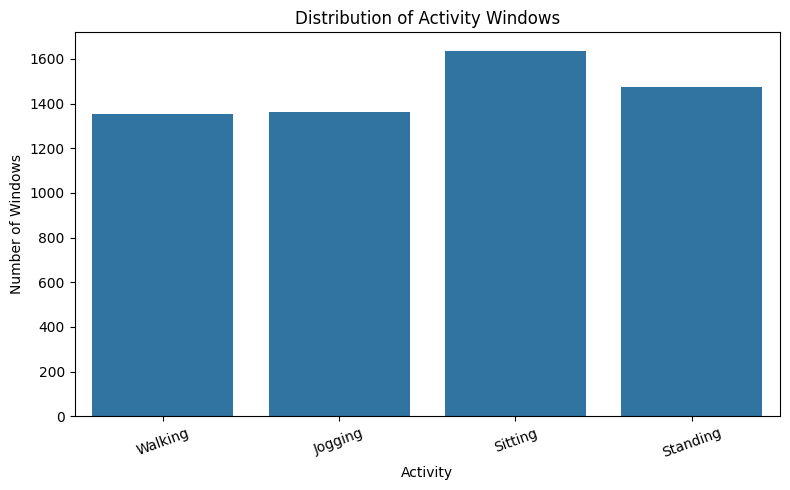

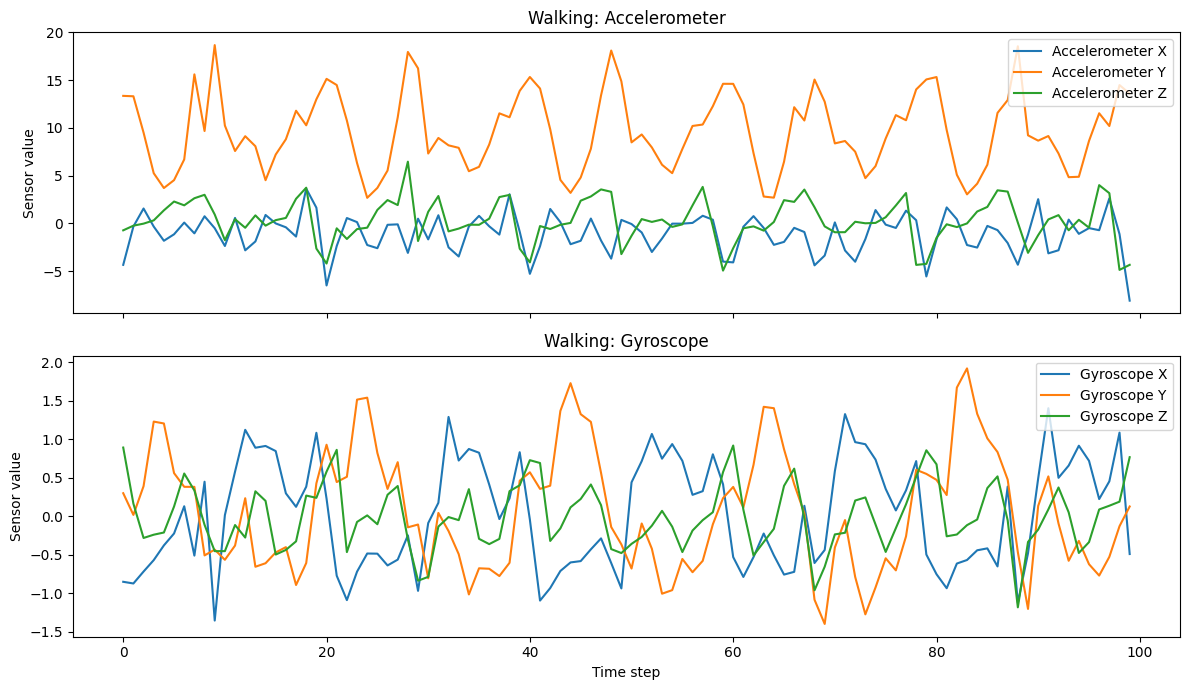

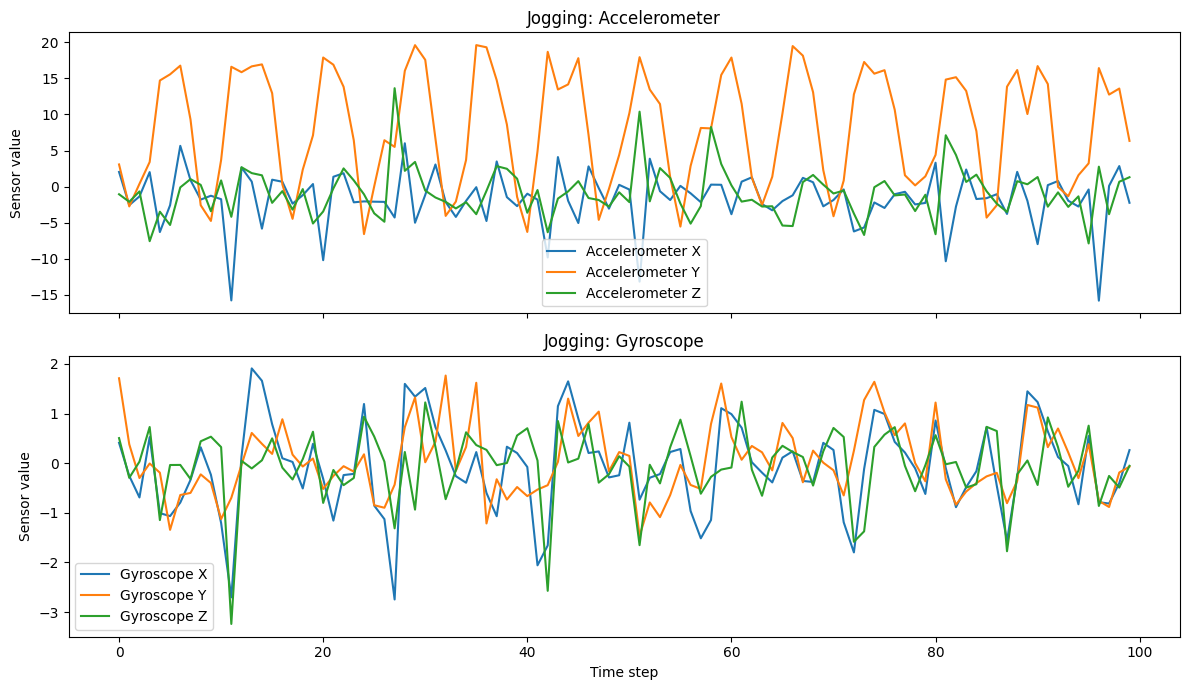

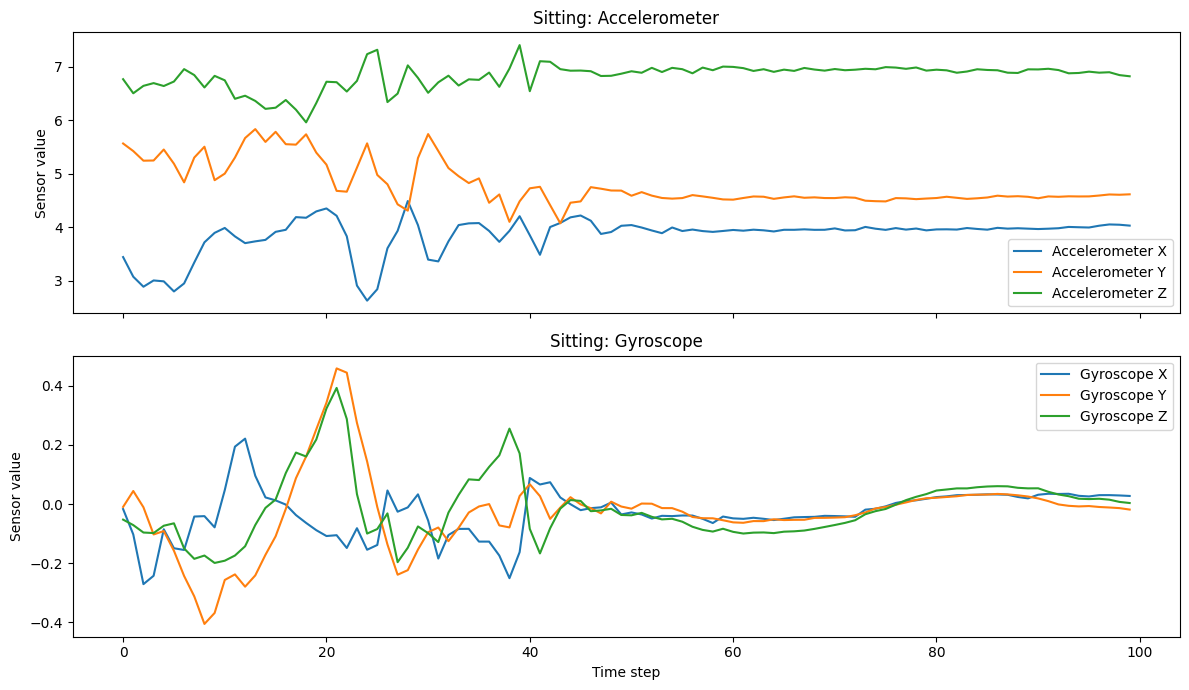

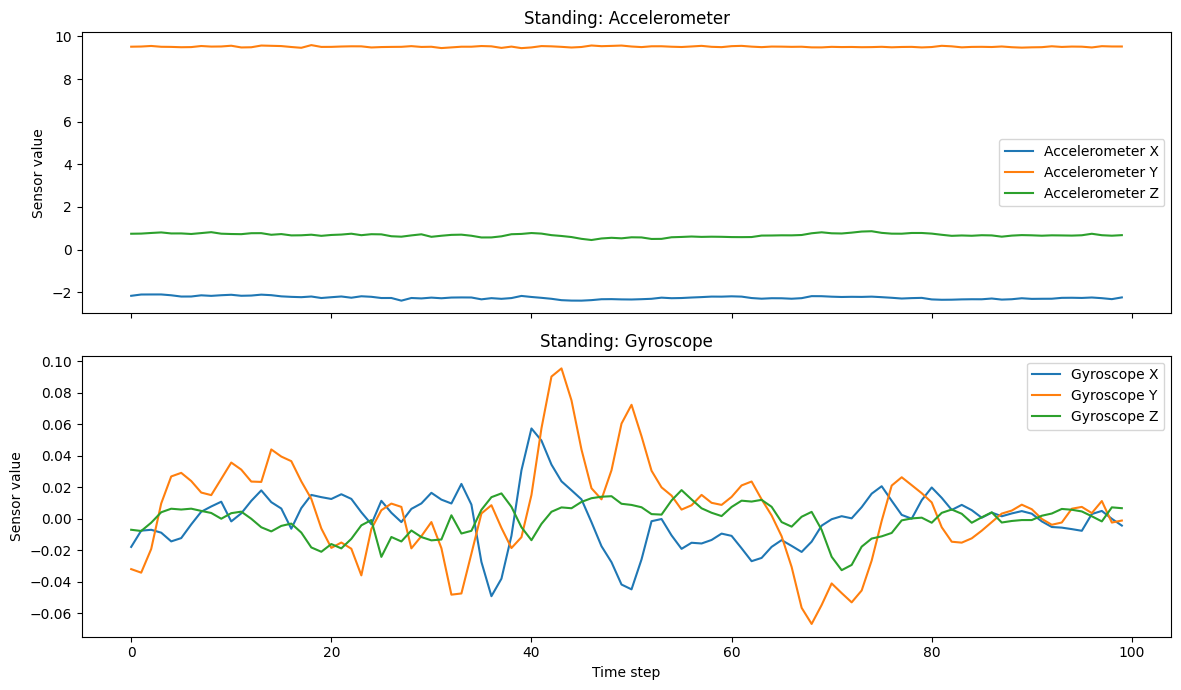

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Activity distribution
activity_counts = pd.Series(y6).map(
    dict(enumerate(activity_names))
).value_counts().reindex(
    activity_names,
    fill_value=0
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=activity_counts.index,
    y=activity_counts.values
)

plt.title("Distribution of Activity Windows")
plt.xlabel("Activity")
plt.ylabel("Number of Windows")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

feature_names = [
    "Accelerometer X",
    "Accelerometer Y",
    "Accelerometer Z",
    "Gyroscope X",
    "Gyroscope Y",
    "Gyroscope Z"
]

for class_id, activity_name in enumerate(activity_names):

    indices = np.where(y6 == class_id)[0]

    if len(indices) == 0:
        print(f"No windows available for {activity_name}")
        continue

    sample_index = indices[0]

    fig, axes = plt.subplots(
        2, 1,
        figsize=(12, 7),
        sharex=True
    )


    for axis in range(3):
        axes[0].plot(
            X6[sample_index, :, axis],
            label=feature_names[axis]
        )

    axes[0].set_title(
        f"{activity_name}: Accelerometer"
    )
    axes[0].set_ylabel("Sensor value")
    axes[0].legend()


    for axis in range(3):
        axes[1].plot(
            X6[sample_index, :, axis + 3],
            label=feature_names[axis + 3]
        )

    axes[1].set_title(
        f"{activity_name}: Gyroscope"
    )
    axes[1].set_xlabel("Time step")
    axes[1].set_ylabel("Sensor value")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [20]:
from sklearn.preprocessing import StandardScaler

scaler6 = StandardScaler()

X6_train = scaler6.fit_transform(
    X6_train.reshape(-1, 6)
).reshape(X6_train.shape)

X6_test = scaler6.transform(
    X6_test.reshape(-1, 6)
).reshape(X6_test.shape)

print("training shape:", X6_train.shape)
print("testing shape:", X6_test.shape)
print("normalization completed")

training shape: (5062, 100, 6)
testing shape: (1353, 100, 6)
normalization completed


In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, LSTM, Dense, Dropout

model6 = Sequential([
    Input(shape=(100, 6)),
    Conv1D(64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(len(np.unique(y6)), activation='softmax')
])

model6.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model6.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 98, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 49, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,452 (142.39 KB)

 Trainable params: 36,452 (142.39 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history6 = model6.fit(
    X6_train,
    y6_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.7046 - loss: 0.7456 - val_accuracy: 0.7226 - val_loss: 1.2763
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.8945 - loss: 0.2864 - val_accuracy: 0.6387 - val_loss: 1.4806
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9429 - loss: 0.1679 - val_accuracy: 0.6732 - val_loss: 1.4138
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.9600 - loss: 0.1277 - val_accuracy: 0.6969 - val_loss: 1.5433
Epoch 5/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.9741 - loss: 0.0966 - val_accuracy: 0.6989 - val_loss: 1.5672
Epoch 6/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - accuracy: 0.9899 - loss: 0.0400 - val_accuracy: 0.6900 - val_loss: 1.7794
Epoch 7/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.9923 - loss: 0.0346 - val_accuracy: 0.6851 - val_loss: 1.9860
Epoch 8/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.9884 - loss: 0.0444 - val_accuracy: 0.6772 

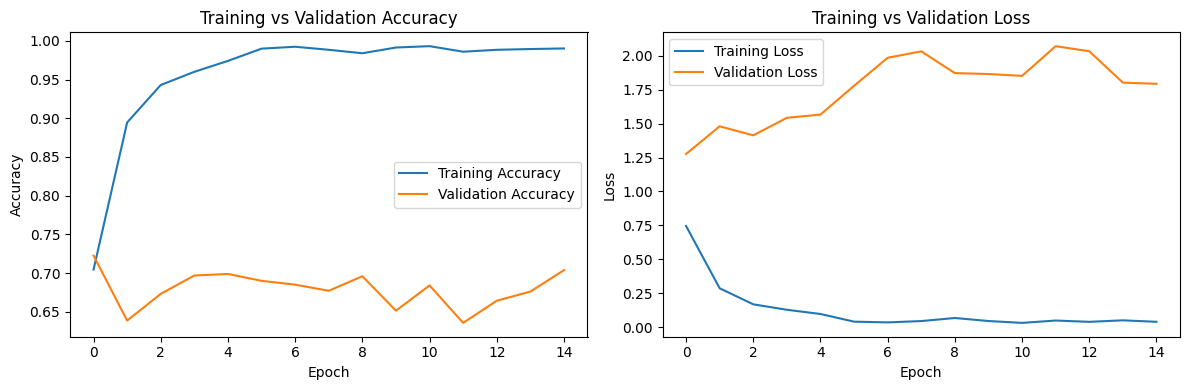

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history6.history["accuracy"], label="Training Accuracy")
plt.plot(history6.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history6.history["loss"], label="Training Loss")
plt.plot(history6.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
              precision    recall  f1-score   support

     Walking       0.84      0.87      0.85       285
     Running       0.89      0.88      0.88       369
     Sitting       0.98      0.92      0.95       359
    Standing       0.92      0.97      0.95       340

    accuracy                           0.91      1353
   macro avg       0.91      0.91      0.91      1353
weighted avg       0.91      0.91      0.91      1353



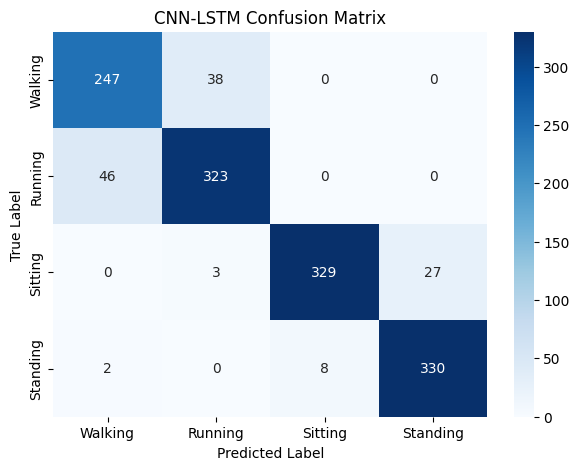

Accuracy per activity:
Walking   : 86.7%
Running   : 87.5%
Sitting   : 91.6%
Standing  : 97.1%

Most confused: Running predicted as Walking (46 times)


In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y6_pred = np.argmax(model6.predict(X6_test), axis=1)

print(classification_report(
    y6_test,
    y6_pred,
    labels=[0, 1, 2, 3],
    target_names=activity_names,
    zero_division=0
))

cm6 = confusion_matrix(y6_test, y6_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm6,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_names,
    yticklabels=activity_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN-LSTM Confusion Matrix")
plt.show()

# Accuracy of each activity
print("Accuracy per activity:")
per_activity_acc = cm6.diagonal() / cm6.sum(axis=1)
for name, acc in zip(activity_names, per_activity_acc):
    print(f"{name:10s}: {acc * 100:.1f}%")

# Which two activities does the model confuse the most?
cm_wrong = cm6.copy()
np.fill_diagonal(cm_wrong, 0)          # ignore correct predictions
a, b = np.unravel_index(cm_wrong.argmax(), cm_wrong.shape)
print(f"\nMost confused: {activity_names[a]} predicted as {activity_names[b]} ({cm_wrong[a, b]} times)")

In [25]:
from sklearn.metrics import accuracy_score

test_loss, test_accuracy = model6.evaluate(X6_test, y6_test, verbose=0)

print("CNN-LSTM Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("CNN-LSTM Test Loss:", round(test_loss, 4))

train_loss, train_accuracy = model6.evaluate(X6_train, y6_train, verbose=0)

print("CNN-LSTM Training Accuracy:", round(train_accuracy * 100, 2), "%")

CNN-LSTM Test Accuracy: 90.84 %
CNN-LSTM Test Loss: 0.5016
CNN-LSTM Training Accuracy: 93.84 %


In [26]:
import os
import json
import numpy as np
from sklearn.metrics import classification_report

os.makedirs("/content/results", exist_ok=True)

model6.save("/content/results/cnn_lstm_model.keras")

y6_pred = np.argmax(model6.predict(X6_test), axis=1)

report = classification_report(
    y6_test,
    y6_pred,
    output_dict=True,
    zero_division=0
)

with open("/content/results/classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

test_loss, test_accuracy = model6.evaluate(
    X6_test, y6_test, verbose=0
)

results = {
    "model": "CNN-LSTM",
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "training_accuracy": float(
        model6.evaluate(X6_train, y6_train, verbose=0)[1]
    )
}

with open("/content/results/model_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model and evaluation results saved successfully.")
print(json.dumps(results, indent=4))

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Model and evaluation results saved successfully.
{
    "model": "CNN-LSTM",
    "test_accuracy": 0.9083518385887146,
    "test_loss": 0.5015752911567688,
    "training_accuracy": 0.9383642673492432
}


In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, GlobalAveragePooling1D, Dense, Dropout
from sklearn.metrics import classification_report
import numpy as np

cnn_model = Sequential([
    Input(shape=(100, 6)),
    Conv1D(64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    GlobalAveragePooling1D(),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(len(np.unique(y6_train)), activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    X6_train,
    y6_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X6_test, y6_test, verbose=0
)

print("CNN Test Accuracy:", round(cnn_accuracy * 100, 2), "%")
print("CNN Test Loss:", round(cnn_loss, 4))

cnn_predictions = np.argmax(cnn_model.predict(X6_test), axis=1)

print(classification_report(y6_test, cnn_predictions, zero_division=0))

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5379 - loss: 1.1540 - val_accuracy: 0.5123 - val_loss: 1.0801
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7629 - loss: 0.7223 - val_accuracy: 0.5913 - val_loss: 0.8767
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8380 - loss: 0.4897 - val_accuracy: 0.6515 - val_loss: 0.7838
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8894 - loss: 0.3563 - val_accuracy: 0.6634 - val_loss: 0.7718
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9076 - loss: 0.2836 - val_accuracy: 0.6703 - val_loss: 0.7979
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9350 - loss: 0.2243 - val_accuracy: 0.6802 - val_loss: 0.8381
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9437 - loss: 0.1979 - val_accuracy: 0.6989 - val_loss: 0.8714
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9558 - loss: 0.1613 - val_accuracy: 0.6940 - v

In [28]:
print("Model Comparison (same test set, unseen participants)")
print("CNN only  : accuracy =", round(cnn_accuracy * 100, 2), "% | loss =", round(cnn_loss, 4))
print("CNN-LSTM  : accuracy =", round(test_accuracy * 100, 2), "% | loss =", round(test_loss, 4))

Model Comparison (same test set, unseen participants)
CNN only  : accuracy = 87.73 % | loss = 0.2861
CNN-LSTM  : accuracy = 90.84 % | loss = 0.5016
